In [1]:
import os
print("Carpeta donde mira el notebook:", os.getcwd())
print("Archivos que ve aquí:", os.listdir())

Carpeta donde mira el notebook: c:\Users\marti\Documents\GitHub\2026-10-BILBAO-FT-Data-Science-LauraML\3-Machine_Learning\Competi_Kaggle_ML
Archivos que ve aquí: ['data', 'datos_limpios.csv', 'datos_limpios_test.csv', 'datos_limpios_train.csv', 'EDA.ipynb', 'Limpieza_datos_test.ipynb', 'Limpieza_datos_train.ipynb', 'ML.ipynb', 'submission.csv']


In [2]:
#1.- CARGAR DATOS

import pandas as pd

df = pd.read_csv('datos_limpios.csv', sep=';', encoding='utf-8')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Company               898 non-null    str    
 1   Product               898 non-null    str    
 2   TypeName              898 non-null    str    
 3   Inches                898 non-null    float64
 4   Ram_GB                898 non-null    int64  
 5   OpSys                 898 non-null    str    
 6   Res_Ancho             898 non-null    int64  
 7   Res_Alto              898 non-null    int64  
 8   Touchscreen           898 non-null    int64  
 9   IPS                   898 non-null    int64  
 10  PPI                   898 non-null    float64
 11  Cpu_GHz               898 non-null    float64
 12  Cpu_Alto_Rendimiento  898 non-null    int64  
 13  Cpu_Gama              898 non-null    str    
 14  SSD_GB                898 non-null    int64  
 15  HDD_GB                898 non-null

In [4]:
df.describe()

,Inches,Ram_GB,Res_Ancho,Res_Alto,Touchscreen,IPS,PPI,Cpu_GHz,Cpu_Alto_Rendimiento,SSD_GB,HDD_GB,Hybrid_GB,Weight,Price_euros
count,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000,898.000000
mean,15.067261,8.387528,1892.240535,1069.585746,0.138085,0.266147,145.967989,2.316771,0.207127,188.209354,427.238307,7.247216,2.055619,1133.967016
std,1.413945,5.125965,494.432247,284.664033,0.345181,0.442188,43.123863,0.501157,0.405473,186.055244,521.396332,83.211053,0.662028,698.142889
min,10.100000,2.000000,1366.000000,768.000000,0.000000,0.000000,90.583402,0.900000,0.000000,0.000000,0.000000,0.000000,0.690000,174.000000
25%,14.000000,4.000000,1600.000000,900.000000,0.000000,0.000000,127.335675,2.000000,0.000000,0.000000,0.000000,0.000000,1.560000,589.640000
50%,15.600000,8.000000,1920.000000,1080.000000,0.000000,0.000000,141.211998,2.500000,0.000000,256.000000,0.000000,0.000000,2.060000,960.500000
75%,15.600000,8.000000,1920.000000,1080.000000,0.000000,1.000000,157.350512,2.700000,0.000000,256.000000,1000.000000,0.000000,2.310000,1499.000000
max,18.400000,64.000000,3840.000000,2160.000000,1.000000,1.000000,352.465147,3.600000,1.000000,1024.000000,2000.000000,1000.000000,4.700000,4899.000000


In [5]:
df.head()

,Company,Product,TypeName,Inches,Ram_GB,OpSys,Res_Ancho,Res_Alto,Touchscreen,IPS,...,Cpu_GHz,Cpu_Alto_Rendimiento,Cpu_Gama,SSD_GB,HDD_GB,Hybrid_GB,Gpu_Marca,Gpu_Gama,Weight,Price_euros
0,Asus,Chromebook Flip,2 in 1 Convertible,12.5,4,Chrome OS,1920,1080,1,0,...,0.9,0,Otro Intel,64,0,0,Intel,Intel Integrada,1.20,669.0
1,Asus,Rog Strix,Gaming,17.3,8,Windows 10,1920,1080,0,0,...,3.2,1,AMD,256,1000,0,AMD,AMD Estándar,3.20,1695.0
2,Lenovo,V310-15IKB,Notebook,15.6,4,Windows 10,1920,1080,0,0,...,2.7,0,Intel Core i7,0,1000,0,Intel,Intel Integrada,1.85,779.0
3,Dell,XPS 13,Ultrabook,13.3,16,Windows 10,3200,1800,1,0,...,2.5,0,Intel Core i7,512,0,0,Intel,Intel Integrada,1.29,2240.0
4,Lenovo,B51-80,Notebook,15.6,4,Windows 7,1920,1080,0,0,...,2.5,0,Intel Core i7,0,0,1000,Intel,Intel Integrada,2.32,825.0


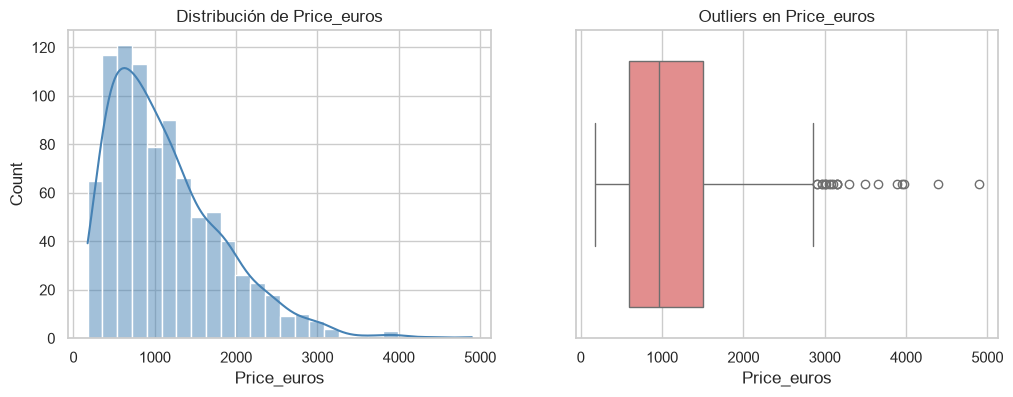

Mediana: 960.50 € | Media: 1133.97 €


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv('datos_limpios.csv', sep=';')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Price_euros'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribución de Price_euros')

sns.boxplot(x=df['Price_euros'], ax=axes[1], color='lightcoral')
axes[1].set_title('Outliers en Price_euros')
plt.show()

print(f"Mediana: {df['Price_euros'].median():.2f} € | Media: {df['Price_euros'].mean():.2f} €")


In [9]:
num_cols = df.select_dtypes(include=[np.number]).columns
comp_corr = pd.DataFrame({
    'Pearson': df[num_cols].corr(method='pearson')['Price_euros'],
    'Spearman': df[num_cols].corr(method='spearman')['Price_euros']
}).sort_values(by='Spearman', ascending=False)

display(comp_corr)


,Pearson,Spearman
Price_euros,1.000000,1.000000
Ram_GB,0.725143,0.766987
SSD_GB,0.658764,0.672663
Res_Ancho,0.553333,0.641176
Res_Alto,0.551213,0.629711
PPI,0.472880,0.521120
Cpu_GHz,0.413746,0.511454
Cpu_Alto_Rendimiento,0.464210,0.455286
IPS,0.286324,0.293988
Touchscreen,0.156956,0.185901


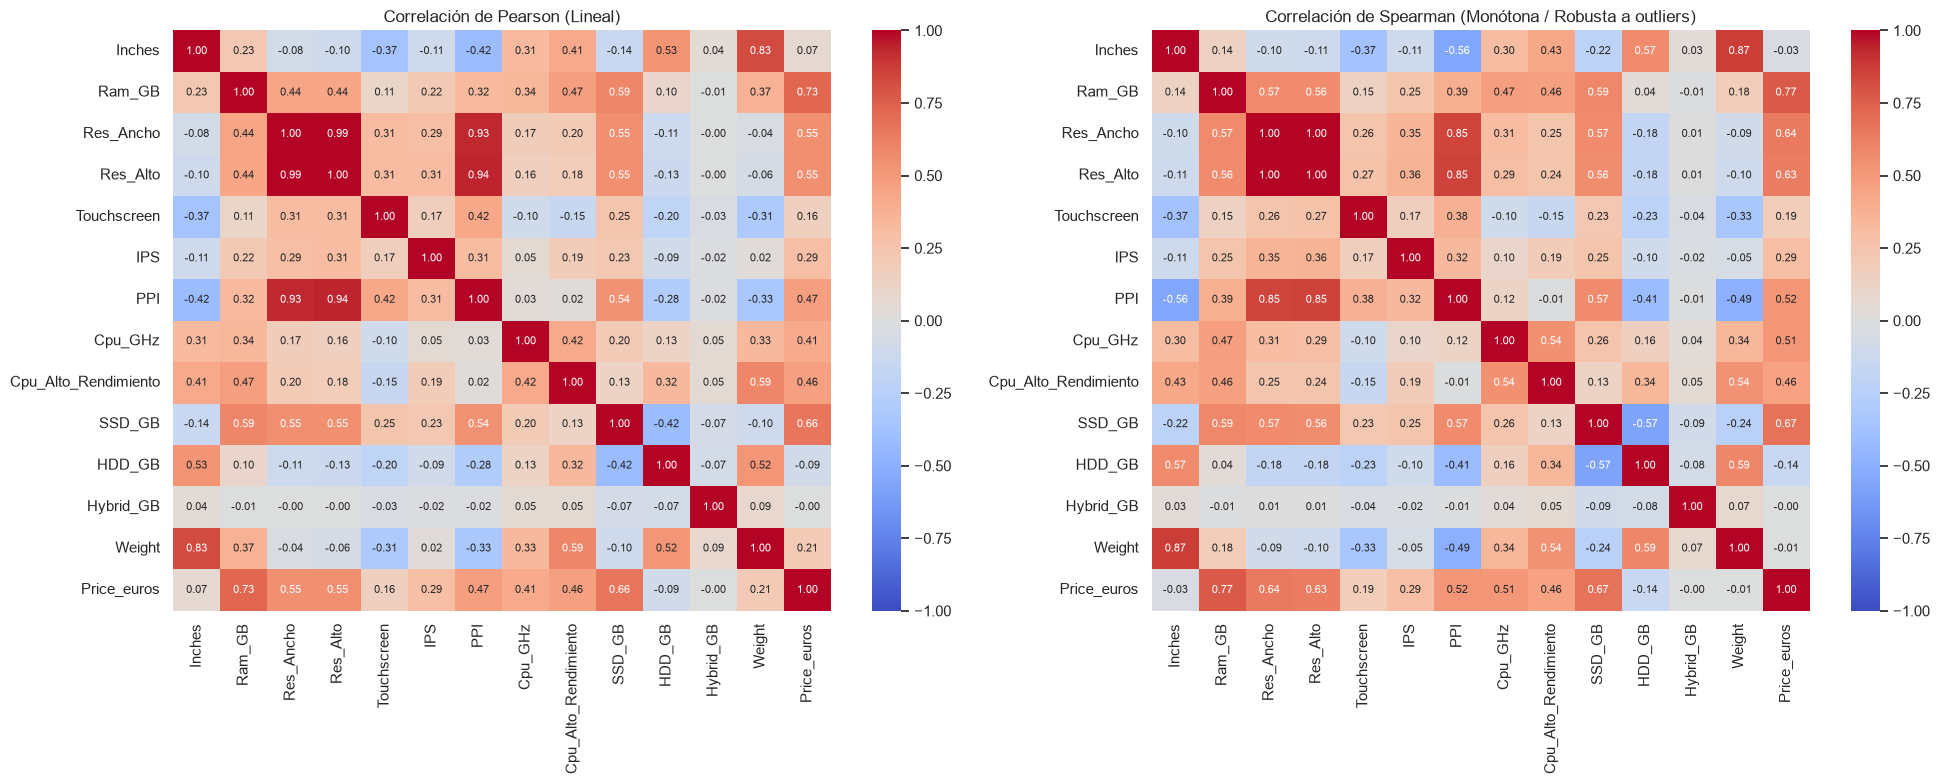

In [12]:
num_cols = df.select_dtypes(include=[np.number]).columns

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Heatmap Pearson
sns.heatmap(df[num_cols].corr(method='pearson'), annot=True, fmt='.2f', 
            cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title('Correlación de Pearson (Lineal)')

# Heatmap Spearman
sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, fmt='.2f', 
            cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], annot_kws={"size": 8})
axes[1].set_title('Correlación de Spearman (Monótona / Robusta a outliers)')

plt.tight_layout()
plt.show()



### Conclusiones del Análisis de Correlación (Pearson y Spearman)

* **Principales motores del precio (`Price_euros`):** Las variables numéricas con mayor impacto positivo son **`Ram_GB`** (0.77 Spearman), **`SSD_GB`** (0.67), la **calidad de pantalla** (`Res_Ancho`, `Res_Alto` y `PPI`, entre 0.47 y 0.64) y la **potencia de CPU** (`Cpu_GHz` 0.51 y `Cpu_Alto_Rendimiento` 0.46).
* **Multicolinealidad alta:** Existen dos grupos fuertemente correlacionados entre sí: **`Res_Ancho` / `Res_Alto` / `PPI`** (0.93 – 1.00) e **`Inches` / `Weight`** (0.83 – 0.87). Para modelos lineales conviene dejar solo `PPI`, mientras que en modelos basados en árboles pueden mantenerse todas.
* **Relaciones no lineales (`Weight` y `HDD_GB`):** 
  * `Weight` cambia de +0.21 (Pearson) a -0.01 (Spearman) porque los equipos más caros se concentran en dos extremos opuestos: *Ultrabooks* muy ligeros (~1 kg) y *Gaming/Workstation* pesados (3–4 kg). Esto favorece el uso de modelos de árboles frente a regresiones lineales.
  * `HDD_GB` tiene correlación negativa (-0.14) al asociarse principalmente a gamas económicas, frente a `SSD_GB` (-0.57 entre ambas).
* **Variables sin aporte relevante:** `Hybrid_GB` (~0.00) apenas tiene representación en el dataset y es candidata a descartarse en el modelado.


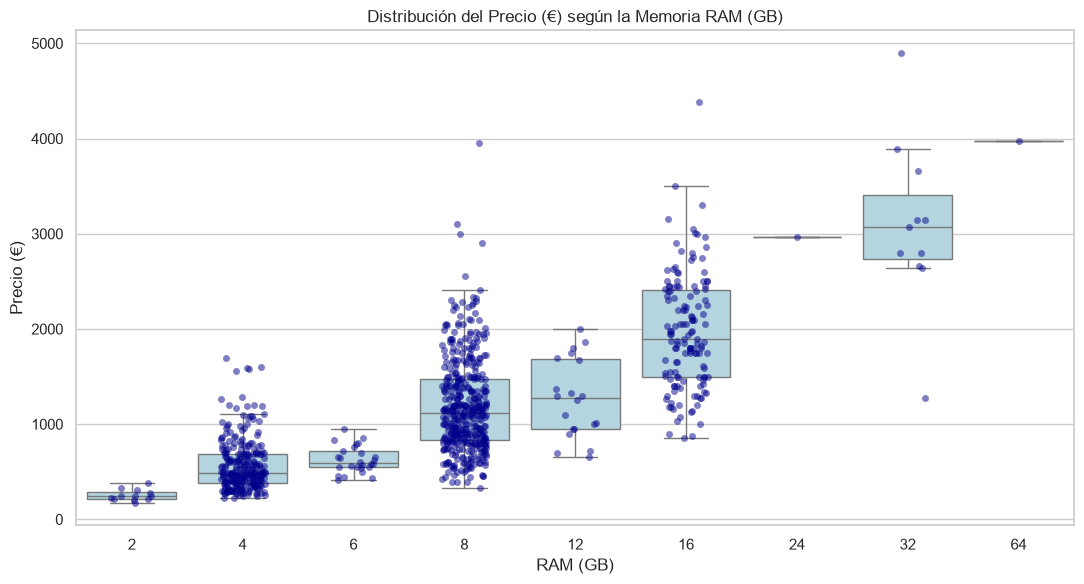

In [16]:
plt.figure(figsize=(11, 6))

# 1. Cajas para ver la mediana y los cuartiles de cada nivel de RAM
sns.boxplot(data=df, x='Ram_GB', y='Price_euros', color='lightblue', showfliers=False)

# 2. Puntos reales encima para ver la cantidad de datos y los outliers
sns.stripplot(data=df, x='Ram_GB', y='Price_euros', color='darkblue', alpha=0.5, jitter=0.2, size=5)

plt.title('Distribución del Precio (€) según la Memoria RAM (GB)')
plt.xlabel('RAM (GB)')
plt.ylabel('Precio (€)')
plt.tight_layout()
plt.show()


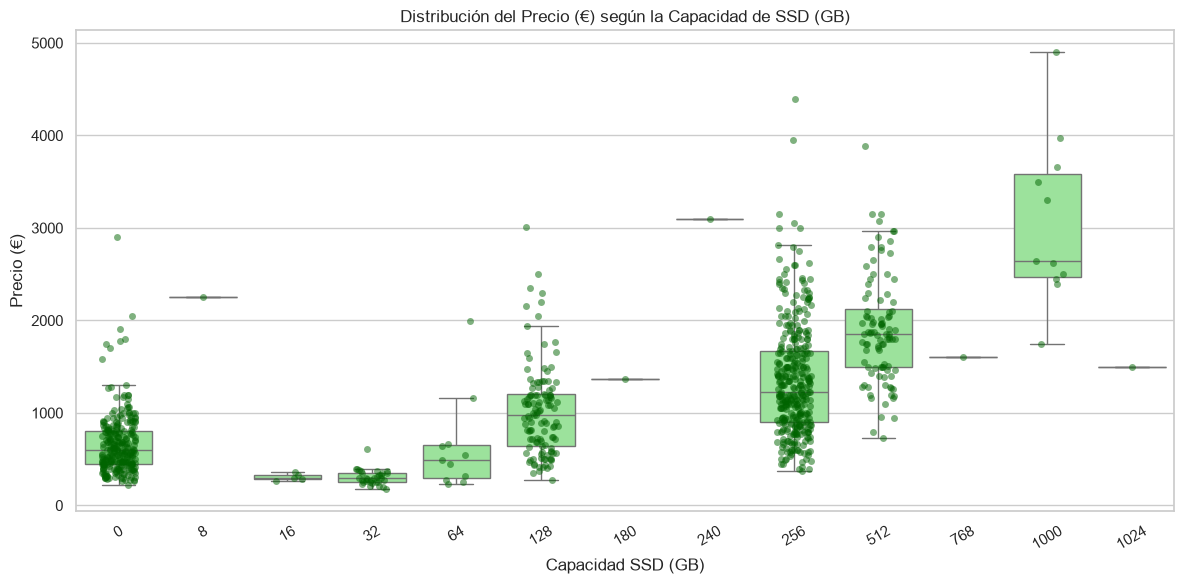

In [17]:
plt.figure(figsize=(12, 6))

# 1. Boxplot para ver medianas y cuartiles de cada capacidad SSD
sns.boxplot(data=df, x='SSD_GB', y='Price_euros', color='lightgreen', showfliers=False)

# 2. Stripplot encima para ver la cantidad de ordenadores y los outliers
sns.stripplot(data=df, x='SSD_GB', y='Price_euros', color='darkgreen', alpha=0.5, jitter=0.2, size=5)

plt.title('Distribución del Precio (€) según la Capacidad de SSD (GB)')
plt.xlabel('Capacidad SSD (GB)')
plt.ylabel('Precio (€)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


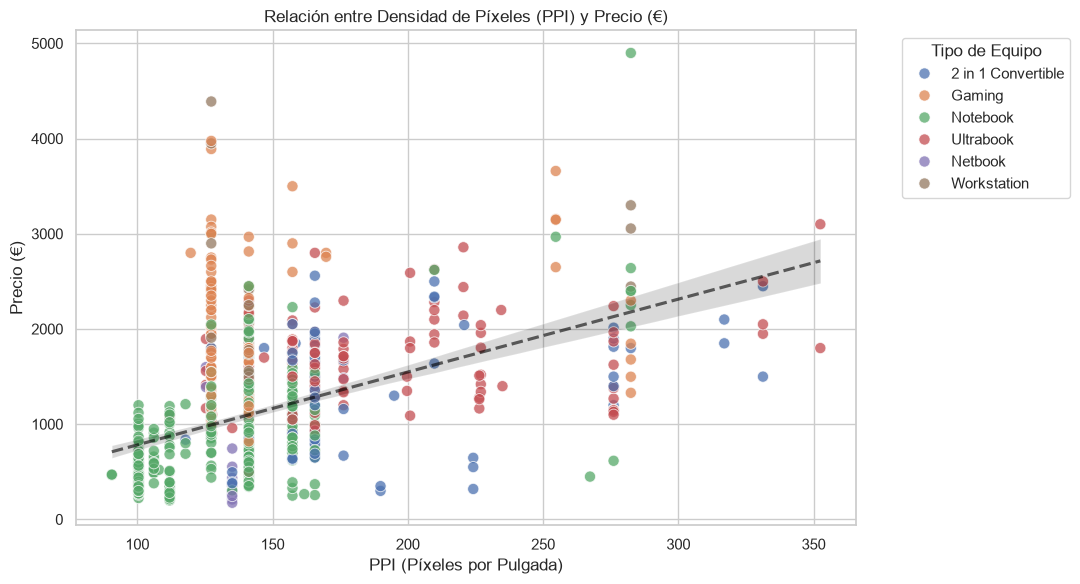

In [18]:
plt.figure(figsize=(11, 6))

# Scatterplot coloreado por tipo de ordenador
sns.scatterplot(data=df, x='PPI', y='Price_euros', hue='TypeName', alpha=0.75, s=65)

# Línea de tendencia general suave para ver cómo sube el precio con el PPI
sns.regplot(data=df, x='PPI', y='Price_euros', scatter=False, color='black', line_kws={'linestyle': '--', 'alpha': 0.6})

plt.title('Relación entre Densidad de Píxeles (PPI) y Precio (€)')
plt.xlabel('PPI (Píxeles por Pulgada)')
plt.ylabel('Precio (€)')
plt.legend(title='Tipo de Equipo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


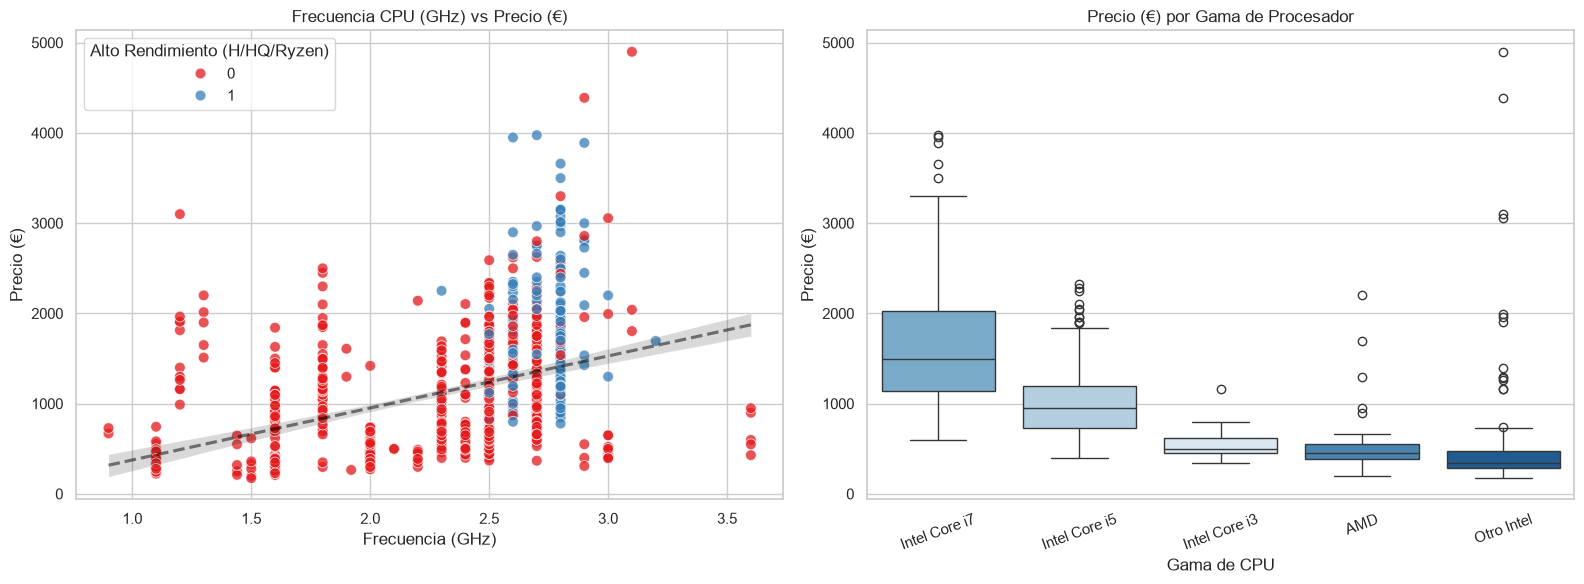

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Frecuencia continua (GHz) vs Precio (coloreado por Alto Rendimiento)
sns.scatterplot(data=df, x='Cpu_GHz', y='Price_euros', hue='Cpu_Alto_Rendimiento', 
                palette='Set1', alpha=0.75, s=60, ax=axes[0])
sns.regplot(data=df, x='Cpu_GHz', y='Price_euros', scatter=False, color='black', 
            line_kws={'linestyle': '--', 'alpha': 0.5}, ax=axes[0])
axes[0].set_title('Frecuencia CPU (GHz) vs Precio (€)')
axes[0].set_xlabel('Frecuencia (GHz)')
axes[0].set_ylabel('Precio (€)')
axes[0].legend(title='Alto Rendimiento (H/HQ/Ryzen)')

# 2. Gama de CPU vs Precio (ordenado por mediana para el MAE)
orden_cpu = df.groupby('Cpu_Gama')['Price_euros'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Cpu_Gama', y='Price_euros', hue='Cpu_Gama', order=orden_cpu, palette='Blues_r', legend=False, ax=axes[1])
axes[1].set_title('Precio (€) por Gama de Procesador')
axes[1].set_xlabel('Gama de CPU')
axes[1].set_ylabel('Precio (€)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()
